# 03 - Exploratory Data Analysis: Credit Card Default

**Input:** `../data/cleaned_readable.csv` (30,000 customers, real NT$ amounts, codes fixed)

**Workflow:**
1. Load and add group columns (age group, limit band)
2. Descriptive statistics
3. Distributions
4. Default rate by key groups
5. Relationships between variables
6. Correlation heatmap
7. Hypothesis tests
8. Key insights

## Step 1: Load and Add Group Columns

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, ttest_ind

df = pd.read_csv("../data/cleaned_readable.csv")

# overall default rate, used as a reference line in the charts
overall_rate = df["default"].mean() * 100

print("Shape:", df.shape)
print("Overall default rate:", round(overall_rate, 2), "%")

Shape: (30000, 33)
Overall default rate: 22.12 %


In [2]:
# pd.cut puts each number into a band
# age: (20, 30] -> "21-30", (30, 40] -> "31-40", ...
df["age_group"] = pd.cut(df["AGE"], bins=[20, 30, 40, 50, 60, 80],
                         labels=["21-30", "31-40", "41-50", "51-60", "61+"])

# credit limit: right=False means the left edge is included, e.g. [50000, 100000)
df["limit_band"] = pd.cut(df["LIMIT_BAL"], bins=[0, 50000, 100000, 200000, 500000, 600000], right=False,
                          labels=["<50K", "50K-100K", "100K-200K", "200K-500K", "500K+"])

df[["AGE", "age_group", "LIMIT_BAL", "limit_band"]].head()

,AGE,age_group,LIMIT_BAL,limit_band
0,24,21-30,20000.0,<50K
1,26,21-30,120000.0,100K-200K
2,34,31-40,90000.0,50K-100K
3,37,31-40,50000.0,50K-100K
4,57,51-60,50000.0,50K-100K


## Step 2: Descriptive Statistics

In [3]:
numeric_cols = ["LIMIT_BAL", "AGE", "PAY_1", "BILL_AMT1", "PAY_AMT1",
                "credit_utilization", "avg_payment_delay", "payment_to_bill_ratio", "months_delayed", "max_delay"]

df[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,166967.49,128013.39,10000.0,50000.00,140000.00,240000.00,525000.00
AGE,30000.0,35.49,9.22,21.0,28.00,34.00,41.00,79.00
PAY_1,30000.0,0.36,0.76,0.0,0.00,0.00,0.00,8.00
BILL_AMT1,30000.0,44311.62,51273.18,0.0,3558.75,22381.50,67091.00,162389.38
PAY_AMT1,30000.0,3496.73,3492.74,0.0,1000.00,2100.00,5006.00,11015.00
credit_utilization,30000.0,0.37,0.35,0.0,0.03,0.29,0.69,5.36
avg_payment_delay,30000.0,0.28,0.60,0.0,0.00,0.00,0.33,6.00
payment_to_bill_ratio,30000.0,0.35,0.38,0.0,0.04,0.11,0.71,1.00
months_delayed,30000.0,0.83,1.55,0.0,0.00,0.00,1.00,6.00
max_delay,30000.0,0.68,1.07,0.0,0.00,0.00,2.00,8.00


In [4]:
# categorical columns
df[["SEX_label", "EDUCATION_label", "MARRIAGE_label", "age_group", "limit_band"]].describe().T

,count,unique,top,freq
SEX_label,30000,2,Female,18112
EDUCATION_label,30000,4,University,14030
MARRIAGE_label,30000,3,Single,15964
age_group,30000,5,21-30,11013
limit_band,30000,5,200K-500K,10222


In [5]:
# mean of each numeric column for defaulters (1) vs non-defaulters (0)
df.groupby("default")[numeric_cols].mean().T.round(3)

default,0,1
LIMIT_BAL,177499.658,129885.877
AGE,35.417,35.726
PAY_1,0.196,0.922
BILL_AMT1,45108.436,41506.203
PAY_AMT1,3763.734,2556.669
credit_utilization,0.352,0.450
avg_payment_delay,0.161,0.706
payment_to_bill_ratio,0.364,0.281
months_delayed,0.504,1.996
max_delay,0.470,1.428


**What we see:** defaulters have a lower credit limit, use more of it, pay a smaller share of their bills and are late more often. Each difference is tested in Step 7.

## Step 3: Distributions

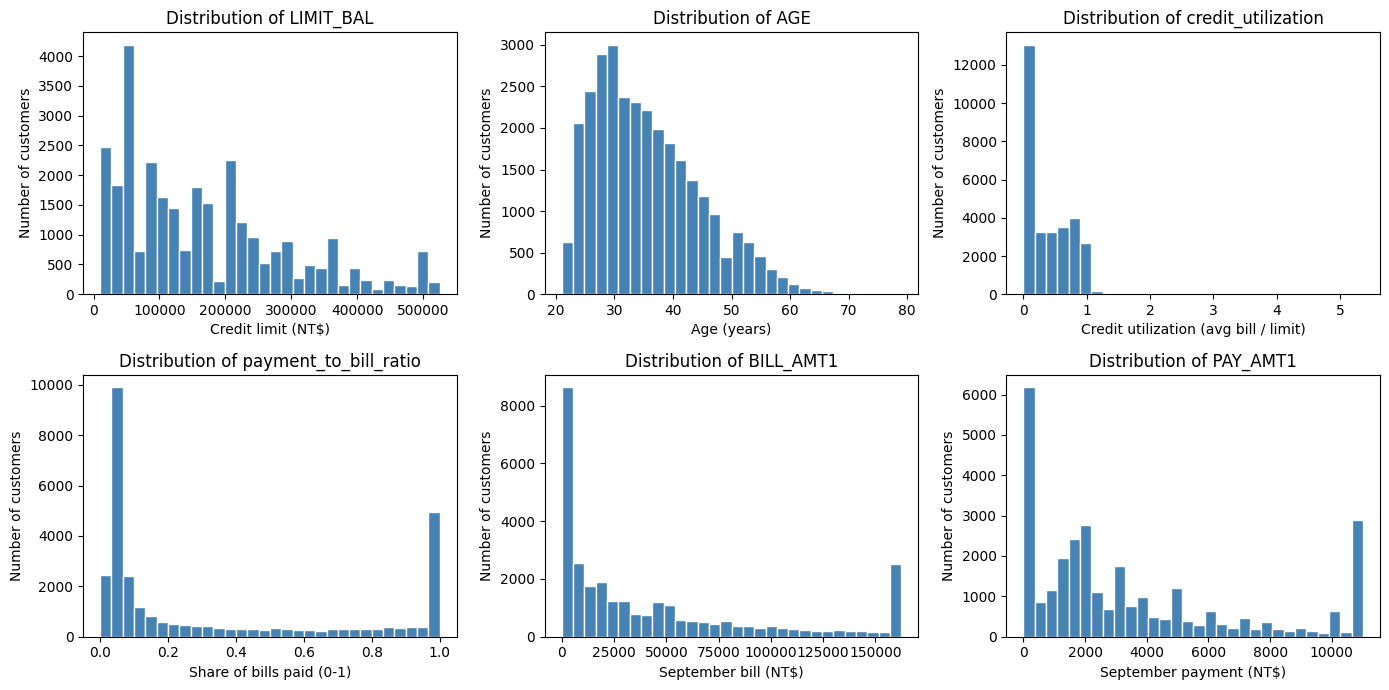

In [6]:
hist_cols = ["LIMIT_BAL", "AGE", "credit_utilization", "payment_to_bill_ratio", "BILL_AMT1", "PAY_AMT1"]
x_labels = ["Credit limit (NT$)", "Age (years)", "Credit utilization (avg bill / limit)",
            "Share of bills paid (0-1)", "September bill (NT$)", "September payment (NT$)"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

# axes.flatten() turns the 2x3 grid into a simple list of 6 charts
for ax, col, label in zip(axes.flatten(), hist_cols, x_labels):
    ax.hist(df[col], bins=30, color="steelblue", edgecolor="white")
    ax.set_title("Distribution of " + col)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of customers")

plt.tight_layout()
plt.show()

**What we see:**
- `LIMIT_BAL`, `AGE` and `credit_utilization` are **right-skewed**: most customers have small to medium limits, are under 40, and use less than half of their limit.
- `BILL_AMT1` and `PAY_AMT1` show a tall bar at the right edge. This is the IQR cap from cleaning.
- `payment_to_bill_ratio` piles up at very low values (around 0.05, paying only a small part) and at 1 (paid everything): two very different customer types.

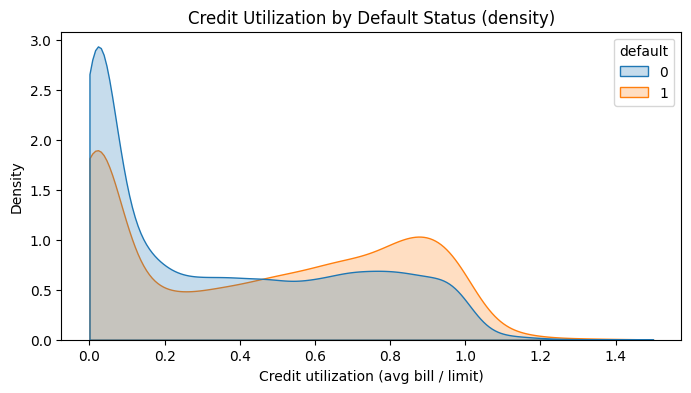

In [7]:
# density plot: credit utilization for defaulters vs non-defaulters
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df, x="credit_utilization", hue="default", common_norm=False, fill=True, clip=(0, 1.5))
plt.title("Credit Utilization by Default Status (density)")
plt.xlabel("Credit utilization (avg bill / limit)")
plt.ylabel("Density")
plt.show()

## Step 4: Default Rate by Key Groups

The red dashed line is the overall default rate (22.12%).

### 4.1 Credit limit band

            count  rate_pct
limit_band                 
<50K         4311     36.07
50K-100K     7139     26.01
100K-200K    7400     20.77
200K-500K   10222     15.49
500K+         928     11.21


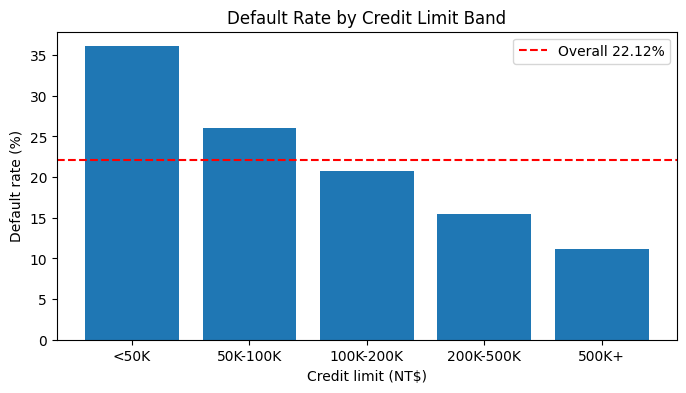

In [8]:
# default rate (%) and number of customers for each group
rate = df.groupby("limit_band", observed=True)["default"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(8, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("Default Rate by Credit Limit Band")
plt.xlabel("Credit limit (NT$)")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

### 4.2 Age group

           count  rate_pct
age_group                 
21-30      11013     22.44
31-40      10713     20.43
41-50       6005     23.30
51-60       1997     25.24
61+          272     26.84


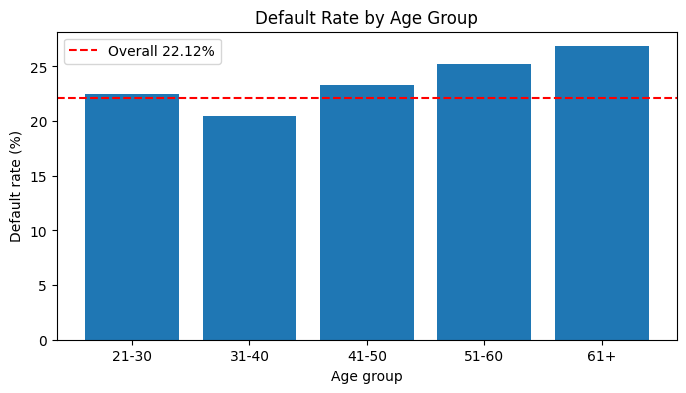

In [9]:
# default rate (%) and number of customers for each group
rate = df.groupby("age_group", observed=True)["default"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(8, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("Default Rate by Age Group")
plt.xlabel("Age group")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

### 4.3 Education

                 count  rate_pct
EDUCATION_label                 
Graduate school  10585     19.23
High school       4917     25.16
Others             468      7.05
University       14030     23.73


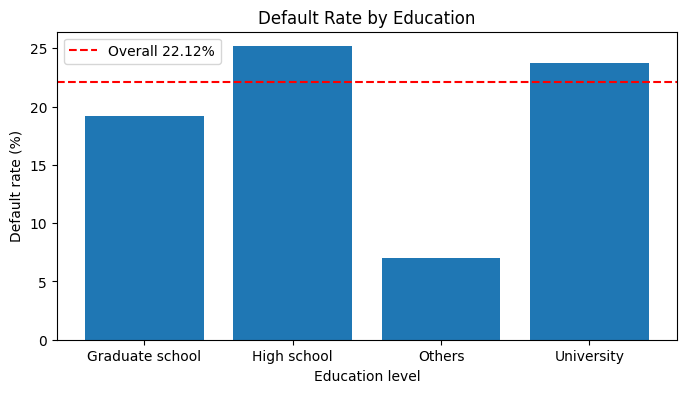

In [10]:
# default rate (%) and number of customers for each group
rate = df.groupby("EDUCATION_label", observed=True)["default"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(8, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("Default Rate by Education")
plt.xlabel("Education level")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

### 4.4 Marital status and sex

                count  rate_pct
MARRIAGE_label                 
Married         13659     23.47
Others            377     23.61
Single          15964     20.93


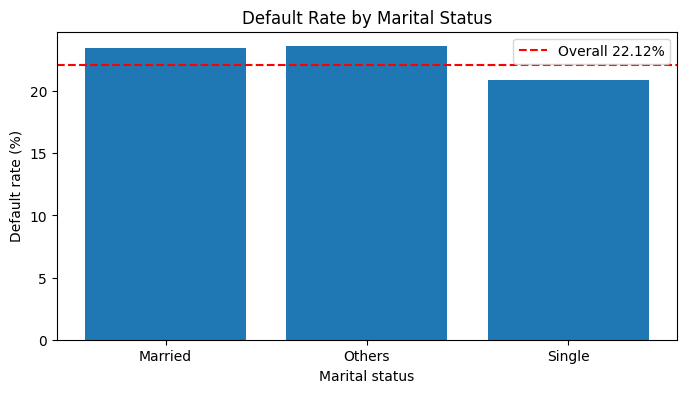

In [11]:
# default rate (%) and number of customers for each group
rate = df.groupby("MARRIAGE_label", observed=True)["default"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(8, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("Default Rate by Marital Status")
plt.xlabel("Marital status")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

           count  rate_pct
SEX_label                 
Female     18112     20.78
Male       11888     24.17


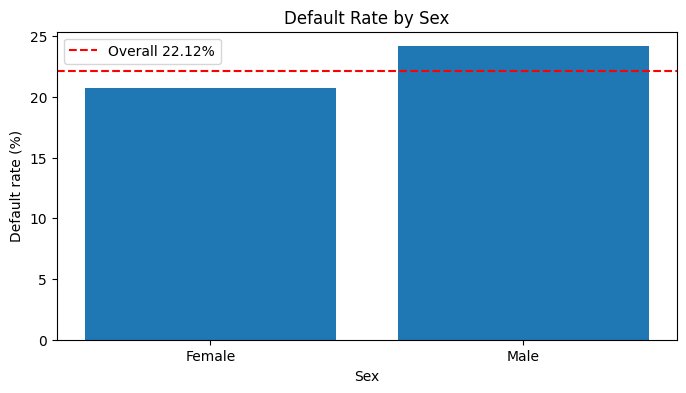

In [12]:
# default rate (%) and number of customers for each group
rate = df.groupby("SEX_label", observed=True)["default"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(8, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("Default Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

### 4.5 Payment delay status

       count  rate_pct
PAY_1                 
0      23182     13.83
1       3688     33.95
2       2667     69.14
3        322     75.78
4         76     68.42
5         26     50.00
6         11     54.55
7          9     77.78
8         19     57.89


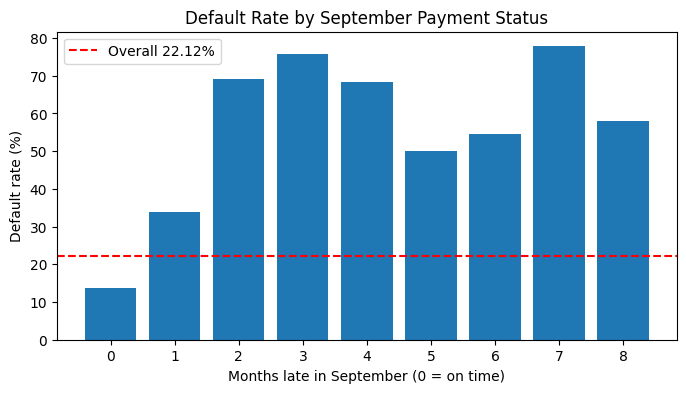

In [13]:
# default rate (%) and number of customers for each group
rate = df.groupby("PAY_1", observed=True)["default"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(8, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("Default Rate by September Payment Status")
plt.xlabel("Months late in September (0 = on time)")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

                count  rate_pct
months_delayed                 
0               19931     11.71
1                4426     29.82
2                1899     38.76
3                1154     50.87
4                 951     57.31
5                 298     57.38
6                1341     70.32


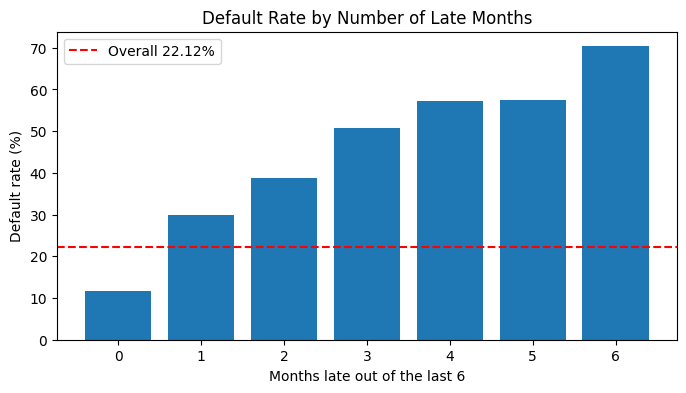

In [14]:
# default rate (%) and number of customers for each group
rate = df.groupby("months_delayed", observed=True)["default"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(8, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("Default Rate by Number of Late Months")
plt.xlabel("Months late out of the last 6")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

**What we see:**
- **Payment delay is by far the biggest driver.** Customers on time in September default 13.83% of the time, against 33.95% if 1 month late and 69.14% if 2 months late.
- By number of late months, the rate goes from 11.71% (never late) to 70.32% (late all 6 months).
- **Credit limit:** the lower the limit, the higher the risk, from 36.07% (<50K) to 11.21% (500K+).
- **Education:** high school (25.16%) and university (23.73%) default more than graduate school (19.23%).
- **Sex:** men 24.17% vs women 20.78%. **Marital status:** married 23.47% vs single 20.93%.
- **Age:** U-shaped. Lowest at 31-40 (20.43%), highest at 61+ (26.84%).

## Step 5: Relationships Between Variables

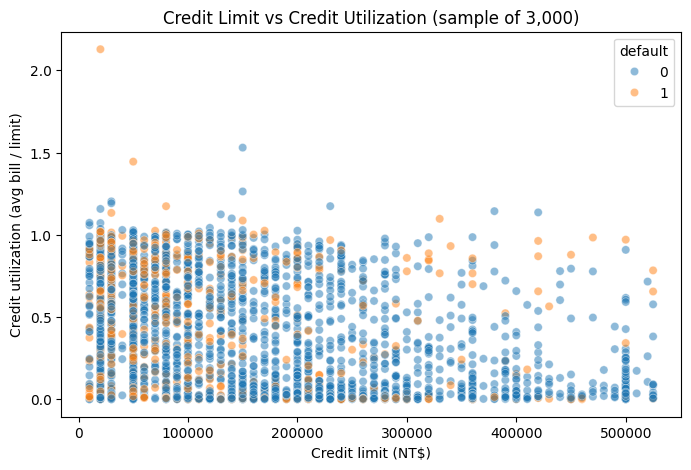

In [15]:
# a random sample of 3,000 customers keeps the scatter plot readable
sample = df.sample(3000, random_state=42)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="LIMIT_BAL", y="credit_utilization", hue="default", alpha=0.5)
plt.title("Credit Limit vs Credit Utilization (sample of 3,000)")
plt.xlabel("Credit limit (NT$)")
plt.ylabel("Credit utilization (avg bill / limit)")
plt.show()

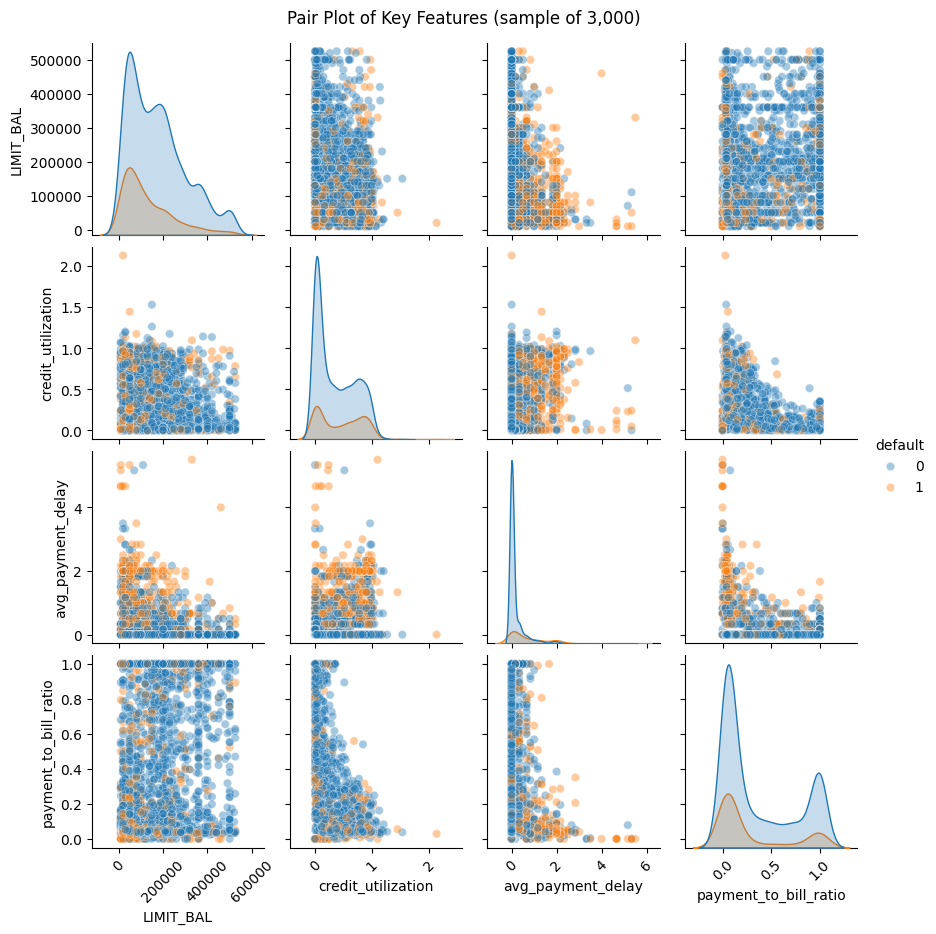

In [16]:
# pair plot of 4 key columns, colored by default
pair = sns.pairplot(sample[["LIMIT_BAL", "credit_utilization", "avg_payment_delay", "payment_to_bill_ratio", "default"]],
                    hue="default", plot_kws={"alpha": 0.4}, height=2.2)
# turn the x-axis numbers so they do not overlap
for ax in pair.axes.flatten():
    ax.tick_params(axis="x", rotation=45)
pair.figure.suptitle("Pair Plot of Key Features (sample of 3,000)", y=1.02)
plt.show()

**What we see:** customers with small limits often run high utilization. Defaulters (orange) gather where `avg_payment_delay` is above 0 and `payment_to_bill_ratio` is low.

## Step 6: Correlation Heatmap

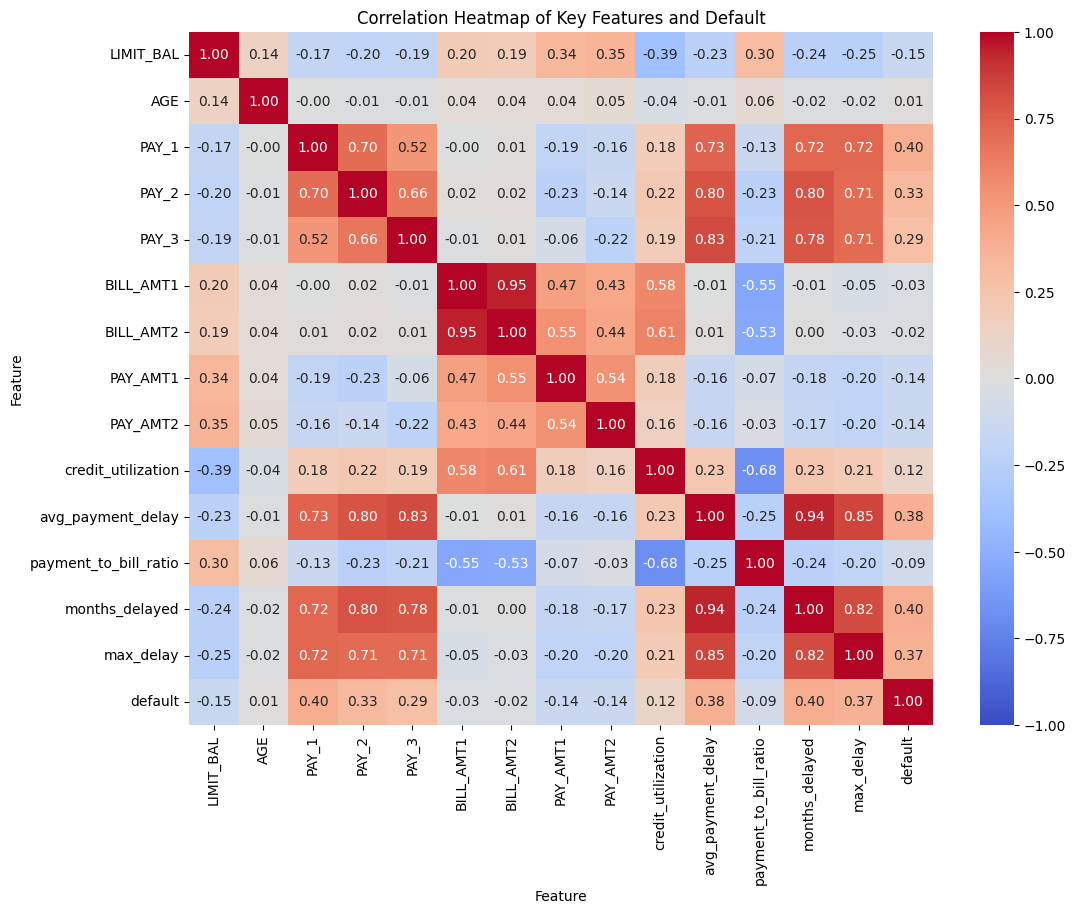

In [17]:
heat_cols = ["LIMIT_BAL", "AGE", "PAY_1", "PAY_2", "PAY_3", "BILL_AMT1", "BILL_AMT2", "PAY_AMT1", "PAY_AMT2",
             "credit_utilization", "avg_payment_delay", "payment_to_bill_ratio", "months_delayed", "max_delay", "default"]
corr = df[heat_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Key Features and Default")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.show()

In [18]:
# correlation of every feature with the target, strongest first
corr["default"].drop("default").sort_values(ascending=False).round(3)

months_delayed           0.398
PAY_1                    0.396
avg_payment_delay        0.376
max_delay                0.370
PAY_2                    0.327
PAY_3                    0.287
credit_utilization       0.116
AGE                      0.014
BILL_AMT2               -0.023
BILL_AMT1               -0.029
payment_to_bill_ratio   -0.091
PAY_AMT2                -0.140
PAY_AMT1                -0.143
LIMIT_BAL               -0.154
Name: default, dtype: float64

**What we see:**
- The delay features have the strongest link to default: `months_delayed` (0.398), `PAY_1` (0.396), `avg_payment_delay` (0.376) and `max_delay` (0.370).
- `LIMIT_BAL` (-0.154) and `PAY_AMT1` (-0.143) are negative: higher limits and bigger payments mean less default.
- `AGE` is almost uncorrelated (0.014).
- The delay features are strongly correlated with each other (mostly 0.70-0.94; e.g. `avg_payment_delay` vs `months_delayed` = 0.94). They carry overlapping information, which matters for reading logistic regression coefficients.

## Step 7: Hypothesis Tests

Significance level: **alpha = 0.05**.
- **Chi-square** for categorical vs default
- **Welch t-test** for a numeric column, defaulters vs non-defaulters (does not assume equal variances)

### Test 1 (chi-square): Sex vs default
H0: default is independent of sex.

In [19]:
table = pd.crosstab(df["SEX_label"], df["default"])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
print("\nChi-square:", round(chi2, 2), "| dof:", dof, "| p-value:", p)
print("Reject H0" if p < 0.05 else "Do not reject H0")

default        0     1
SEX_label             
Female     14349  3763
Male        9015  2873

Chi-square: 47.71 | dof: 1 | p-value: 4.944678999412026e-12
Reject H0


**Interpretation:** p ≈ 5e-12 < 0.05. Default depends on sex: men default more (24.17% vs 20.78%).

### Test 2 (chi-square): Education vs default
H0: default is independent of education level.

In [20]:
table = pd.crosstab(df["EDUCATION_label"], df["default"])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
print("\nChi-square:", round(chi2, 2), "| dof:", dof, "| p-value:", p)
print("Reject H0" if p < 0.05 else "Do not reject H0")

default              0     1
EDUCATION_label             
Graduate school   8549  2036
High school       3680  1237
Others             435    33
University       10700  3330

Chi-square: 160.41 | dof: 3 | p-value: 1.4950645648106153e-34
Reject H0


**Interpretation:** p ≈ 1.5e-34 < 0.05. Education is linked to default; graduate-school customers default least among the main groups.

### Test 3 (chi-square): Marital status vs default
H0: default is independent of marital status.

In [21]:
table = pd.crosstab(df["MARRIAGE_label"], df["default"])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
print("\nChi-square:", round(chi2, 2), "| dof:", dof, "| p-value:", p)
print("Reject H0" if p < 0.05 else "Do not reject H0")

default             0     1
MARRIAGE_label             
Married         10453  3206
Others            288    89
Single          12623  3341

Chi-square: 28.13 | dof: 2 | p-value: 7.790720364202813e-07
Reject H0


**Interpretation:** p ≈ 7.8e-07 < 0.05. Marital status matters, but the gap is small (married 23.47% vs single 20.93%).

### Test 4 (t-test): Credit limit, defaulters vs non-defaulters
H0: mean `LIMIT_BAL` is the same in both groups.

In [22]:
defaulted = df.loc[df["default"] == 1, "LIMIT_BAL"]
not_defaulted = df.loc[df["default"] == 0, "LIMIT_BAL"]

print("Mean limit, defaulters:", round(defaulted.mean(), 0))
print("Mean limit, non-defaulters:", round(not_defaulted.mean(), 0))

t_stat, p = ttest_ind(defaulted, not_defaulted, equal_var=False)
print("\nt-statistic:", round(t_stat, 2), "| p-value:", p)
print("Reject H0" if p < 0.05 else "Do not reject H0")

Mean limit, defaulters: 129886.0
Mean limit, non-defaulters: 177500.0

t-statistic: -29.0 | p-value: 8.828749628565293e-179
Reject H0


**Interpretation:** p ≈ 9e-179 < 0.05. Defaulters have a much lower average limit (about NT$130K vs NT$177K).

### Test 5 (t-test): Credit utilization, defaulters vs non-defaulters
H0: mean `credit_utilization` is the same in both groups.

In [23]:
defaulted = df.loc[df["default"] == 1, "credit_utilization"]
not_defaulted = df.loc[df["default"] == 0, "credit_utilization"]

print("Mean utilization, defaulters:", round(defaulted.mean(), 3))
print("Mean utilization, non-defaulters:", round(not_defaulted.mean(), 3))

t_stat, p = ttest_ind(defaulted, not_defaulted, equal_var=False)
print("\nt-statistic:", round(t_stat, 2), "| p-value:", p)
print("Reject H0" if p < 0.05 else "Do not reject H0")

Mean utilization, defaulters: 0.45
Mean utilization, non-defaulters: 0.352

t-statistic: 19.39 | p-value: 2.7488939703941606e-82
Reject H0


**Interpretation:** p ≈ 3e-82 < 0.05. Defaulters use more of their limit (45.0% vs 35.2% on average).

### Test 6 (t-test): Age, defaulters vs non-defaulters
H0: mean `AGE` is the same in both groups.

In [24]:
defaulted = df.loc[df["default"] == 1, "AGE"]
not_defaulted = df.loc[df["default"] == 0, "AGE"]

print("Mean age, defaulters:", round(defaulted.mean(), 2))
print("Mean age, non-defaulters:", round(not_defaulted.mean(), 2))

t_stat, p = ttest_ind(defaulted, not_defaulted, equal_var=False)
print("\nt-statistic:", round(t_stat, 2), "| p-value:", p)
print("Reject H0" if p < 0.05 else "Do not reject H0")

Mean age, defaulters: 35.73
Mean age, non-defaulters: 35.42

t-statistic: 2.32 | p-value: 0.02038649025587465
Reject H0


**Interpretation:** p = 0.020 < 0.05, so it is technically significant, but the difference is only about 0.3 years (35.73 vs 35.42). Age on its own is not a useful risk signal; the U-shape in Step 4 matters more than the mean.

**A note on large samples:** with 30,000 customers, even tiny differences (like 0.3 years of age) become "significant". Always look at the size of the difference too.

## Step 8: Key Insights

1. **Payment history is the strongest signal.** Default rises from 13.83% (on time in September) to 69.14% (2 months late), and from 11.71% (never late) to 70.32% (late all 6 months).
2. **Lower credit limits mean higher risk:** 36.07% default below NT$50K vs 11.21% at NT$500K+.
3. **Higher utilization and paying a smaller share of the bill** are both linked to default.
4. **Demographics matter less.** Sex, education and marital status are significant, but the gaps are only 2.5-6 points.
5. **Age alone is almost useless** (correlation 0.014, mean difference 0.3 years).

These insights are summarised in `../docs/insights.md`.